# LLM Assignment 2 — Task 2
## Linear Regression Using a Multi-Layer Neural Network From Scratch

This notebook implements **Task 2 and both Bonus Questions** from the assignment.

### Required network
```text
2 → 5 → 3 → 1
```

- Input: 2 neurons (`MedInc`, `HouseAge`)
- Hidden layer 1: 5 neurons + ReLU
- Hidden layer 2: 3 neurons + ReLU
- Output: 1 neuron

### Required optimizers
- Gradient Descent
- Momentum
- Adam

### Required learning rates
- 0.01
- 0.001

### Bonus
1. Add a third hidden layer with 2 neurons.
2. Add L2 regularization.

The neural network, forward propagation, backpropagation, and optimizer updates are implemented manually. `sklearn` is used only to load the California Housing dataset specified in the assignment.

## 1. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.datasets import fetch_california_housing

np.random.seed(42)


## 2. Load the California Housing Dataset

The assignment specifies `fetch_california_housing`.

We use:
- `MedInc` — Median Income
- `HouseAge` — House Age

Target:
- `MedHouseVal` — Median House Value

In [2]:
housing = fetch_california_housing(as_frame=True)

X = housing.data[["MedInc", "HouseAge"]].to_numpy(dtype=float)
y = housing.target.to_numpy(dtype=float).reshape(-1, 1)

print("Features:", ["MedInc", "HouseAge"])
print("X shape:", X.shape)
print("Target:", housing.target.name)
print("y shape:", y.shape)


Features: ['MedInc', 'HouseAge']
X shape: (20640, 2)
Target: MedHouseVal
y shape: (20640, 1)


## 3. 80/20 Train-Test Split

The split is performed manually so that the preprocessing and data handling remain transparent.

In [3]:
def train_test_split_manual(X, y, test_size=0.2, seed=42):
    rng = np.random.default_rng(seed)
    indices = np.arange(len(X))
    rng.shuffle(indices)

    split = int(len(X) * (1 - test_size))

    train_idx = indices[:split]
    test_idx = indices[split:]

    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]


X_train, X_test, y_train, y_test = train_test_split_manual(
    X, y, test_size=0.2, seed=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 16512
Testing samples: 4128


## 4. Normalize the Features

We normalize using statistics calculated **only from the training data**:

$$
X_{norm} = \frac{X-\mu}{\sigma}
$$

This prevents information from the test set from influencing training.

In [4]:
train_mean = X_train.mean(axis=0)
train_std = X_train.std(axis=0)
train_std[train_std == 0] = 1.0

X_train_norm = (X_train - train_mean) / train_std
X_test_norm = (X_test - train_mean) / train_std

print("Training mean:", train_mean)
print("Training std:", train_std)


Training mean: [ 3.8716266  28.70724322]
Training std: [ 1.90161359 12.60605401]


## 5. ReLU Activation

Both hidden layers use ReLU:

$$
ReLU(z)=\max(0,z)
$$

Its derivative is:

$$
ReLU'(z)=
\begin{cases}
1 & z>0\\
0 & z\leq0
\end{cases}
$$

The output layer is linear because this is a regression problem.

In [5]:
def relu(z):
    return np.maximum(0, z)


def relu_derivative(z):
    return (z > 0).astype(float)


def mse_loss(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)


def mse_gradient(y_true, y_pred):
    return 2 * (y_pred - y_true) / y_true.shape[0]


# 6. Required Network: 2 → 5 → 3 → 1

Forward propagation:

$$
Z_1=XW_1+b_1
$$
$$
A_1=ReLU(Z_1)
$$
$$
Z_2=A_1W_2+b_2
$$
$$
A_2=ReLU(Z_2)
$$
$$
\hat y=A_2W_3+b_3
$$

We use He initialization because the hidden layers use ReLU.

In [6]:
class NeuralNetwork:
    def __init__(self, input_size=2, hidden1_size=5,
                 hidden2_size=3, output_size=1):
        self.W1 = np.random.randn(input_size, hidden1_size) * np.sqrt(2 / input_size)
        self.b1 = np.zeros((1, hidden1_size))

        self.W2 = np.random.randn(hidden1_size, hidden2_size) * np.sqrt(2 / hidden1_size)
        self.b2 = np.zeros((1, hidden2_size))

        self.W3 = np.random.randn(hidden2_size, output_size) * np.sqrt(2 / hidden2_size)
        self.b3 = np.zeros((1, output_size))

    def forward(self, X):
        self.Z1 = X @ self.W1 + self.b1
        self.A1 = relu(self.Z1)

        self.Z2 = self.A1 @ self.W2 + self.b2
        self.A2 = relu(self.Z2)

        self.Z3 = self.A2 @ self.W3 + self.b3
        self.y_hat = self.Z3

        return self.y_hat

    def backward(self, X, y):
        m = X.shape[0]

        dZ3 = mse_gradient(y, self.y_hat)
        dW3 = self.A2.T @ dZ3
        db3 = np.sum(dZ3, axis=0, keepdims=True)

        dA2 = dZ3 @ self.W3.T
        dZ2 = dA2 * relu_derivative(self.Z2)
        dW2 = self.A1.T @ dZ2
        db2 = np.sum(dZ2, axis=0, keepdims=True)

        dA1 = dZ2 @ self.W2.T
        dZ1 = dA1 * relu_derivative(self.Z1)
        dW1 = X.T @ dZ1
        db1 = np.sum(dZ1, axis=0, keepdims=True)

        return {
            "W1": dW1, "b1": db1,
            "W2": dW2, "b2": db2,
            "W3": dW3, "b3": db3
        }


## 7. Optimizer Implementations

### Gradient Descent

$$
\theta_{t+1}=\theta_t-\alpha g_t
$$

### Momentum

$$
v_t=\beta v_{t-1}+g_t
$$
$$
\theta_{t+1}=\theta_t-\alpha v_t
$$

### Adam

Adam maintains first and second moments and applies bias correction before updating the parameters.


In [7]:
def gd_update(model, grads, lr):
    for key in grads:
        if key == "W1": model.W1 -= lr * grads[key]
        elif key == "b1": model.b1 -= lr * grads[key]
        elif key == "W2": model.W2 -= lr * grads[key]
        elif key == "b2": model.b2 -= lr * grads[key]
        elif key == "W3": model.W3 -= lr * grads[key]
        elif key == "b3": model.b3 -= lr * grads[key]


def create_velocity(model):
    return {
        "W1": np.zeros_like(model.W1), "b1": np.zeros_like(model.b1),
        "W2": np.zeros_like(model.W2), "b2": np.zeros_like(model.b2),
        "W3": np.zeros_like(model.W3), "b3": np.zeros_like(model.b3)
    }


def momentum_update(model, grads, velocity, lr, beta=0.9):
    for key in velocity:
        velocity[key] = beta * velocity[key] + grads[key]

        if key == "W1": model.W1 -= lr * velocity[key]
        elif key == "b1": model.b1 -= lr * velocity[key]
        elif key == "W2": model.W2 -= lr * velocity[key]
        elif key == "b2": model.b2 -= lr * velocity[key]
        elif key == "W3": model.W3 -= lr * velocity[key]
        elif key == "b3": model.b3 -= lr * velocity[key]

    return velocity


def create_adam_state(model):
    m = create_velocity(model)
    v = create_velocity(model)
    return m, v


def adam_update(model, grads, m, v, t, lr,
                beta1=0.9, beta2=0.999, epsilon=1e-8):
    for key in m:
        m[key] = beta1 * m[key] + (1 - beta1) * grads[key]
        v[key] = beta2 * v[key] + (1 - beta2) * (grads[key] ** 2)

        m_hat = m[key] / (1 - beta1 ** t)
        v_hat = v[key] / (1 - beta2 ** t)

        update = lr * m_hat / (np.sqrt(v_hat) + epsilon)

        if key == "W1": model.W1 -= update
        elif key == "b1": model.b1 -= update
        elif key == "W2": model.W2 -= update
        elif key == "b2": model.b2 -= update
        elif key == "W3": model.W3 -= update
        elif key == "b3": model.b3 -= update

    return m, v


## 8. Training Function

For a fair comparison, each optimizer/learning-rate experiment starts from the same initialization seed.

In [8]:
def train_model(X_train, y_train, optimizer_name,
                lr, epochs=1000, seed=42):
    np.random.seed(seed)

    model = NeuralNetwork()
    losses = []

    if optimizer_name == "Momentum":
        velocity = create_velocity(model)

    if optimizer_name == "Adam":
        m, v = create_adam_state(model)

    start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        pred = model.forward(X_train)
        loss = mse_loss(y_train, pred)
        losses.append(loss)

        grads = model.backward(X_train, y_train)

        if optimizer_name == "Gradient Descent":
            gd_update(model, grads, lr)

        elif optimizer_name == "Momentum":
            velocity = momentum_update(
                model, grads, velocity, lr
            )

        elif optimizer_name == "Adam":
            m, v = adam_update(
                model, grads, m, v, epoch, lr
            )

    elapsed = time.perf_counter() - start

    return model, np.array(losses), elapsed


# 9. Required Experiments

Optimizers:
- Gradient Descent
- Momentum
- Adam

Learning rates:
- 0.01
- 0.001

In [9]:
optimizers = ["Gradient Descent", "Momentum", "Adam"]
learning_rates = [0.01, 0.001]

results = {}

for optimizer_name in optimizers:
    results[optimizer_name] = {}

    for lr in learning_rates:
        model, losses, elapsed = train_model(
            X_train_norm, y_train,
            optimizer_name, lr,
            epochs=1000,
            seed=42
        )

        test_pred = model.forward(X_test_norm)
        test_mse = mse_loss(y_test, test_pred)

        results[optimizer_name][lr] = {
            "model": model,
            "losses": losses,
            "time": elapsed,
            "test_mse": test_mse,
            "predictions": test_pred
        }

print("Required experiments completed.")


Required experiments completed.


## 10. Required Results

In [10]:
for optimizer_name in optimizers:
    for lr in learning_rates:
        r = results[optimizer_name][lr]

        print(
            f"{optimizer_name:18s} | "
            f"LR={lr:<5} | "
            f"Train MSE={r['losses'][-1]:.6f} | "
            f"Test MSE={r['test_mse']:.6f} | "
            f"Time={r['time']:.4f}s"
        )


Gradient Descent   | LR=0.01  | Train MSE=0.677049 | Test MSE=0.690856 | Time=5.6372s
Gradient Descent   | LR=0.001 | Train MSE=1.391723 | Test MSE=1.403645 | Time=5.8395s
Momentum           | LR=0.01  | Train MSE=0.616038 | Test MSE=0.626382 | Time=3.0442s
Momentum           | LR=0.001 | Train MSE=0.681942 | Test MSE=0.695260 | Time=2.9460s
Adam               | LR=0.01  | Train MSE=0.629863 | Test MSE=0.640979 | Time=2.9620s
Adam               | LR=0.001 | Train MSE=0.672282 | Test MSE=0.674156 | Time=4.4078s


## 11. Training-Loss Curves

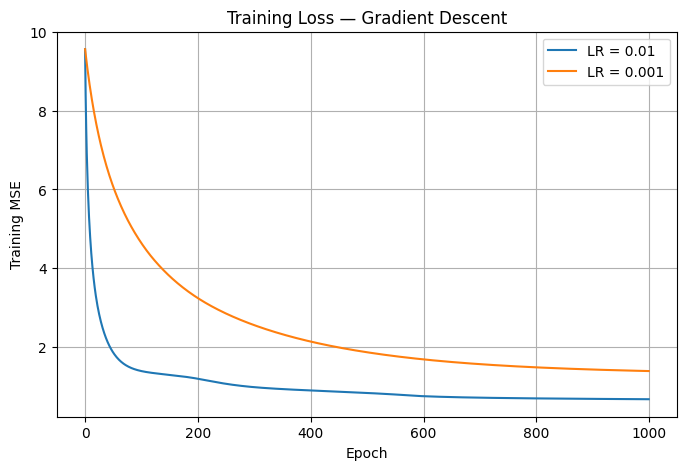

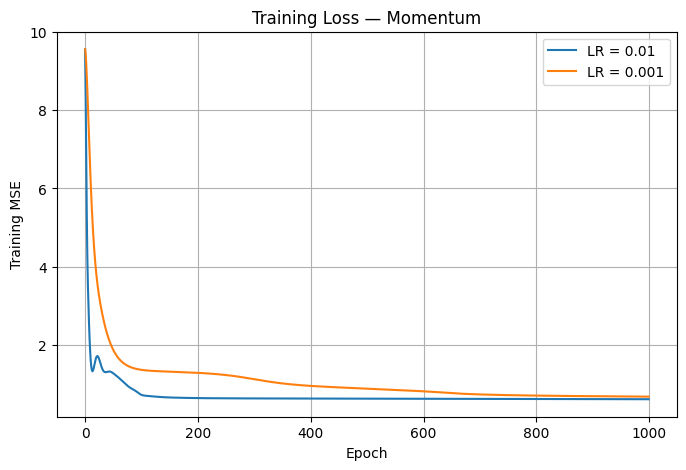

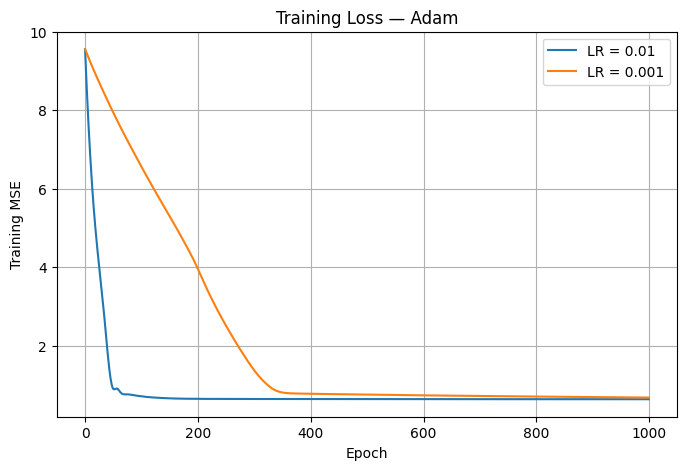

In [11]:
for optimizer_name in optimizers:
    plt.figure(figsize=(8, 5))

    for lr in learning_rates:
        plt.plot(
            results[optimizer_name][lr]["losses"],
            label=f"LR = {lr}"
        )

    plt.xlabel("Epoch")
    plt.ylabel("Training MSE")
    plt.title(f"Training Loss — {optimizer_name}")
    plt.legend()
    plt.grid(True)
    plt.show()


## 12. Predicted vs Actual Values

For a perfect regression model, all points would lie on:

$$
y_{pred}=y_{actual}
$$

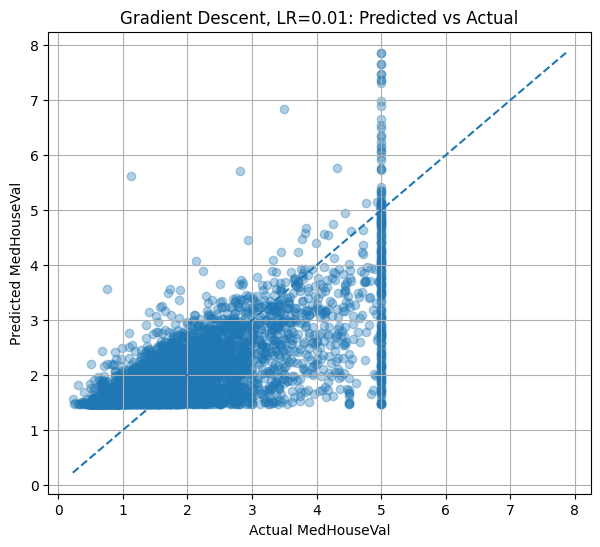

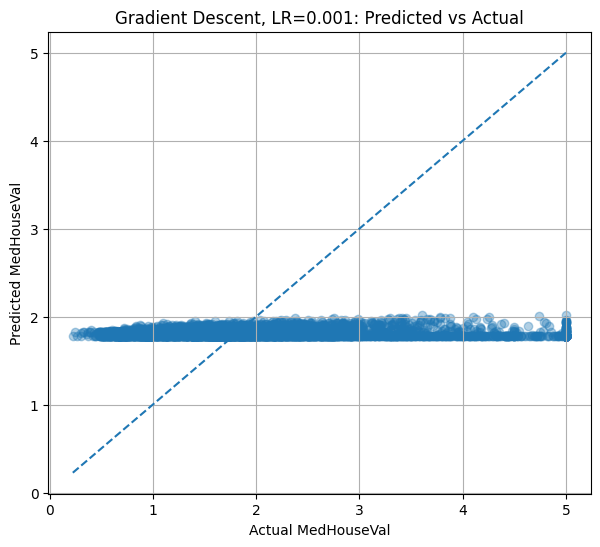

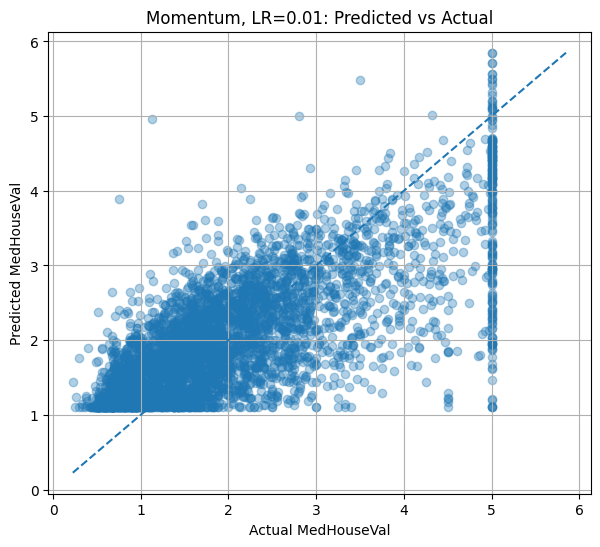

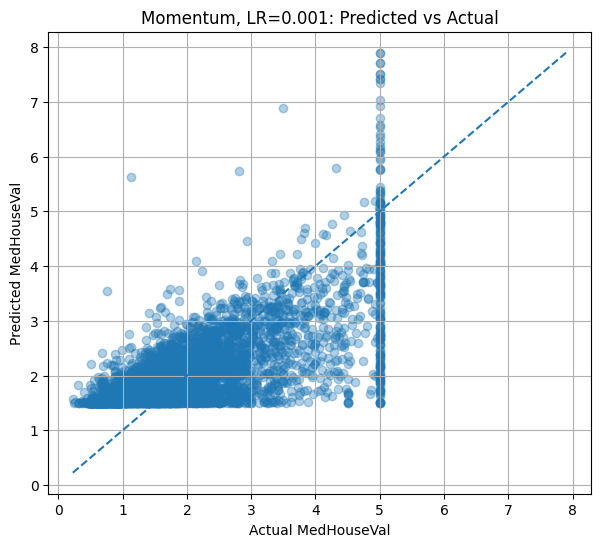

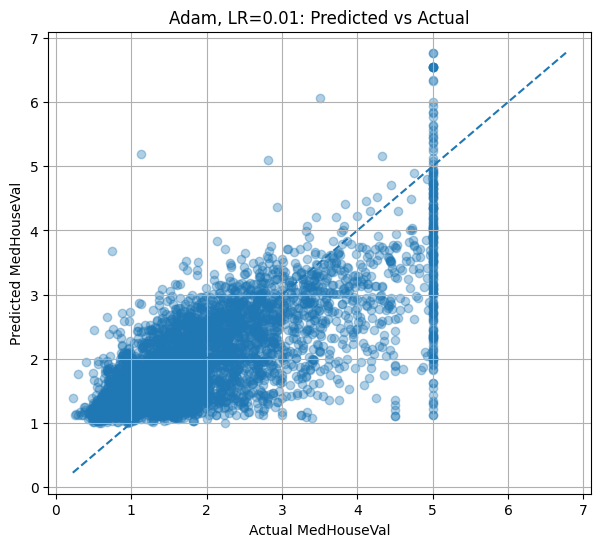

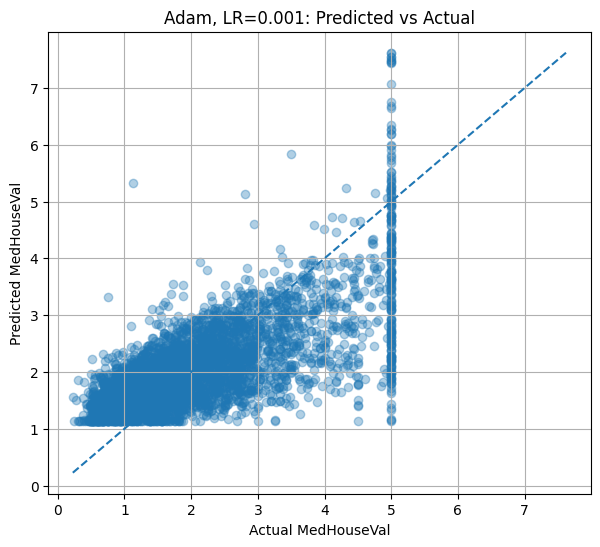

In [12]:
for optimizer_name in optimizers:
    for lr in learning_rates:
        pred = results[optimizer_name][lr]["predictions"]

        plt.figure(figsize=(7, 6))
        plt.scatter(y_test, pred, alpha=0.35)

        lo = min(y_test.min(), pred.min())
        hi = max(y_test.max(), pred.max())

        plt.plot([lo, hi], [lo, hi], linestyle="--")

        plt.xlabel("Actual MedHouseVal")
        plt.ylabel("Predicted MedHouseVal")
        plt.title(f"{optimizer_name}, LR={lr}: Predicted vs Actual")
        plt.grid(True)
        plt.show()


## 12A. Required Results — Interpretation

The required experiments use the two specified learning rates, 0.01 and 0.001, for Gradient Descent, Momentum, and Adam. For each run, the notebook reports:

- final training MSE,
- test MSE,
- training time,
- training-loss convergence curve.

The **test MSE** is the main quantitative measure used to compare final regression performance. The loss curves show how quickly and smoothly each optimizer converges.

Because all models use the same train/test split, architecture, initialization seed, number of epochs, and preprocessing, the optimizer and learning-rate comparisons are directly comparable.

A lower test MSE indicates better generalization to unseen California Housing samples. A faster decrease in training MSE indicates faster optimization, but the lowest training loss is not automatically the best test result.


# BONUS 1 — Additional Hidden Layer

The assignment asks for a third hidden layer with **2 neurons**.

Original:
```text
2 → 5 → 3 → 1
```

Bonus:
```text
2 → 5 → 3 → 2 → 1
```

The extra layer increases the model's capacity. We compare its performance with the original architecture.

In [13]:
class DeepNeuralNetwork:
    def __init__(self):
        self.W1 = np.random.randn(2, 5) * np.sqrt(2 / 2)
        self.b1 = np.zeros((1, 5))

        self.W2 = np.random.randn(5, 3) * np.sqrt(2 / 5)
        self.b2 = np.zeros((1, 3))

        self.W3 = np.random.randn(3, 2) * np.sqrt(2 / 3)
        self.b3 = np.zeros((1, 2))

        self.W4 = np.random.randn(2, 1) * np.sqrt(2 / 2)
        self.b4 = np.zeros((1, 1))

    def forward(self, X):
        self.Z1 = X @ self.W1 + self.b1
        self.A1 = relu(self.Z1)

        self.Z2 = self.A1 @ self.W2 + self.b2
        self.A2 = relu(self.Z2)

        self.Z3 = self.A2 @ self.W3 + self.b3
        self.A3 = relu(self.Z3)

        self.Z4 = self.A3 @ self.W4 + self.b4
        self.y_hat = self.Z4

        return self.y_hat

    def backward(self, X, y):
        m = X.shape[0]

        dZ4 = mse_gradient(y, self.y_hat)
        dW4 = self.A3.T @ dZ4
        db4 = np.sum(dZ4, axis=0, keepdims=True)

        dA3 = dZ4 @ self.W4.T
        dZ3 = dA3 * relu_derivative(self.Z3)
        dW3 = self.A2.T @ dZ3
        db3 = np.sum(dZ3, axis=0, keepdims=True)

        dA2 = dZ3 @ self.W3.T
        dZ2 = dA2 * relu_derivative(self.Z2)
        dW2 = self.A1.T @ dZ2
        db2 = np.sum(dZ2, axis=0, keepdims=True)

        dA1 = dZ2 @ self.W2.T
        dZ1 = dA1 * relu_derivative(self.Z1)
        dW1 = X.T @ dZ1
        db1 = np.sum(dZ1, axis=0, keepdims=True)

        return {
            "W1": dW1, "b1": db1,
            "W2": dW2, "b2": db2,
            "W3": dW3, "b3": db3,
            "W4": dW4, "b4": db4
        }


## Bonus 1 Training Function

We use Adam and both required learning rates for the architecture comparison.

In [14]:
def train_deep_model(X_train, y_train, lr,
                      epochs=1000, seed=42):
    np.random.seed(seed)
    model = DeepNeuralNetwork()

    m = {
        "W1": np.zeros_like(model.W1), "b1": np.zeros_like(model.b1),
        "W2": np.zeros_like(model.W2), "b2": np.zeros_like(model.b2),
        "W3": np.zeros_like(model.W3), "b3": np.zeros_like(model.b3),
        "W4": np.zeros_like(model.W4), "b4": np.zeros_like(model.b4)
    }
    v = {key: np.zeros_like(value) for key, value in m.items()}

    losses = []
    start = time.perf_counter()

    for t in range(1, epochs + 1):
        pred = model.forward(X_train)
        losses.append(mse_loss(y_train, pred))

        grads = model.backward(X_train, y_train)

        for key in m:
            m[key] = 0.9 * m[key] + 0.1 * grads[key]
            v[key] = 0.999 * v[key] + 0.001 * grads[key] ** 2

            m_hat = m[key] / (1 - 0.9 ** t)
            v_hat = v[key] / (1 - 0.999 ** t)

            update = lr * m_hat / (np.sqrt(v_hat) + 1e-8)

            if key == "W1": model.W1 -= update
            elif key == "b1": model.b1 -= update
            elif key == "W2": model.W2 -= update
            elif key == "b2": model.b2 -= update
            elif key == "W3": model.W3 -= update
            elif key == "b3": model.b3 -= update
            elif key == "W4": model.W4 -= update
            elif key == "b4": model.b4 -= update

    elapsed = time.perf_counter() - start
    return model, np.array(losses), elapsed


## Run Bonus 1

In [15]:
bonus1 = {}

for lr in learning_rates:
    model, losses, elapsed = train_deep_model(
        X_train_norm, y_train,
        lr=lr,
        epochs=1000,
        seed=42
    )

    pred = model.forward(X_test_norm)
    test_mse = mse_loss(y_test, pred)

    bonus1[lr] = {
        "model": model,
        "losses": losses,
        "test_mse": test_mse,
        "time": elapsed
    }

    print(
        f"Bonus architecture 2→5→3→2→1 | "
        f"LR={lr} | Train MSE={losses[-1]:.6f} | "
        f"Test MSE={test_mse:.6f} | Time={elapsed:.4f}s"
    )


Bonus architecture 2→5→3→2→1 | LR=0.01 | Train MSE=0.619861 | Test MSE=0.633882 | Time=3.9827s
Bonus architecture 2→5→3→2→1 | LR=0.001 | Train MSE=0.667749 | Test MSE=0.681811 | Time=4.0840s


## Bonus 1 Comparison

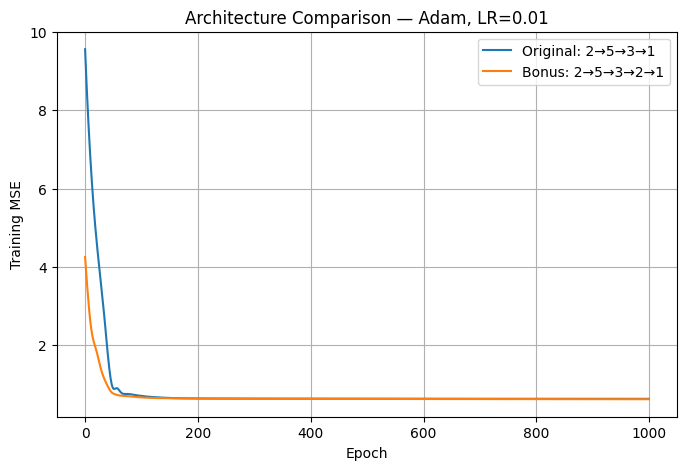

LR = 0.01
Original test MSE: 0.640979
Bonus test MSE:   0.633882


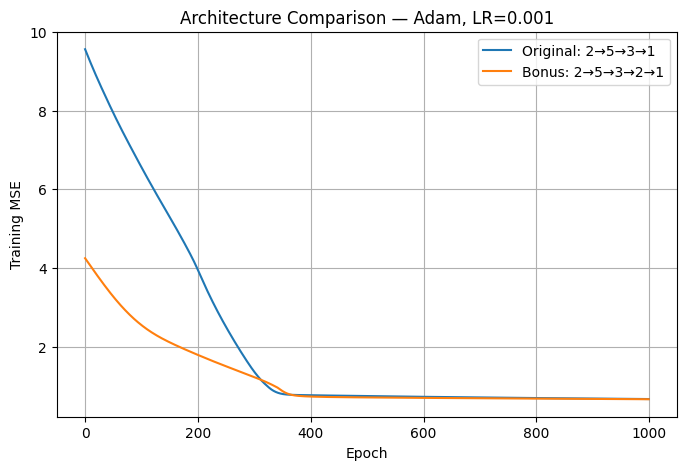

LR = 0.001
Original test MSE: 0.674156
Bonus test MSE:   0.681811


In [16]:
for lr in learning_rates:
    plt.figure(figsize=(8, 5))

    plt.plot(
        results["Adam"][lr]["losses"],
        label="Original: 2→5→3→1"
    )
    plt.plot(
        bonus1[lr]["losses"],
        label="Bonus: 2→5→3→2→1"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Training MSE")
    plt.title(f"Architecture Comparison — Adam, LR={lr}")
    plt.legend()
    plt.grid(True)
    plt.show()

    print(f"LR = {lr}")
    print(f"Original test MSE: {results['Adam'][lr]['test_mse']:.6f}")
    print(f"Bonus test MSE:   {bonus1[lr]['test_mse']:.6f}")


# BONUS 2 — L2 Regularization

L2 regularization adds a penalty for large weights.

$$
L_{total}
=
MSE+
\frac{\lambda}{2}
\left(
||W_1||^2+||W_2||^2+||W_3||^2
\right)
$$

The derivative of the penalty with respect to a weight matrix is:

$$
\lambda W
$$

Therefore, `lambda * W` is added to each weight gradient.

Biases are not regularized in this implementation.

In [17]:
def l2_penalty(model):
    return 0.5 * (
        np.sum(model.W1 ** 2)
        + np.sum(model.W2 ** 2)
        + np.sum(model.W3 ** 2)
    )


def train_l2_model(X_train, y_train, lr=0.001,
                   lambda_reg=0.001,
                   epochs=1000, seed=42):
    np.random.seed(seed)
    model = NeuralNetwork()

    m, v = create_adam_state(model)

    mse_losses = []
    total_losses = []

    start = time.perf_counter()

    for t in range(1, epochs + 1):
        pred = model.forward(X_train)

        mse = mse_loss(y_train, pred)
        total = mse + lambda_reg * l2_penalty(model)

        mse_losses.append(mse)
        total_losses.append(total)

        grads = model.backward(X_train, y_train)

        # L2 penalty applies to weights, not biases.
        grads["W1"] += lambda_reg * model.W1
        grads["W2"] += lambda_reg * model.W2
        grads["W3"] += lambda_reg * model.W3

        m, v = adam_update(
            model, grads, m, v, t, lr
        )

    elapsed = time.perf_counter() - start

    return model, np.array(mse_losses), np.array(total_losses), elapsed


## Run Bonus 2

We compare:
- `λ = 0` → no regularization
- `λ = 0.001` → L2 regularization

Adam and learning rate `0.001` are used for this focused comparison.

In [18]:
regularization_results = {}

for lambda_reg in [0.0, 0.001]:
    model, mse_losses, total_losses, elapsed = train_l2_model(
        X_train_norm,
        y_train,
        lr=0.001,
        lambda_reg=lambda_reg,
        epochs=1000,
        seed=42
    )

    pred = model.forward(X_test_norm)
    test_mse = mse_loss(y_test, pred)

    regularization_results[lambda_reg] = {
        "model": model,
        "mse_losses": mse_losses,
        "total_losses": total_losses,
        "test_mse": test_mse,
        "time": elapsed
    }

    print(
        f"Lambda={lambda_reg} | "
        f"Train MSE={mse_losses[-1]:.6f} | "
        f"Test MSE={test_mse:.6f} | "
        f"Time={elapsed:.4f}s"
    )


Lambda=0.0 | Train MSE=0.672282 | Test MSE=0.674156 | Time=3.8427s
Lambda=0.001 | Train MSE=0.665852 | Test MSE=0.668685 | Time=2.9786s


## Bonus 2 Comparison

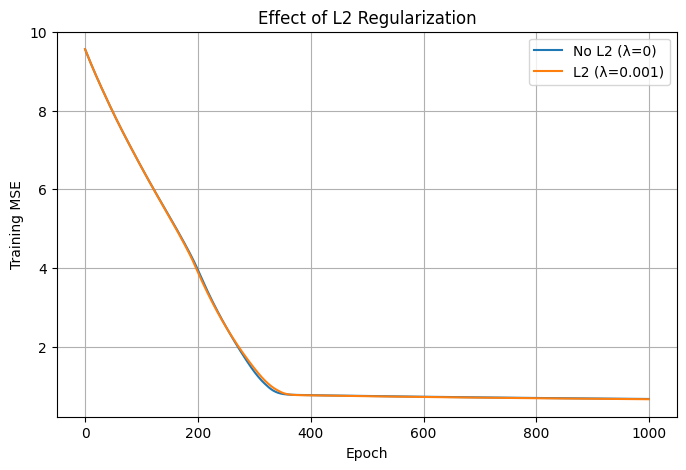

No L2 test MSE: 0.6741556708952638
L2 test MSE: 0.668684979243403


In [19]:
plt.figure(figsize=(8, 5))

plt.plot(
    regularization_results[0.0]["mse_losses"],
    label="No L2 (λ=0)"
)
plt.plot(
    regularization_results[0.001]["mse_losses"],
    label="L2 (λ=0.001)"
)

plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Effect of L2 Regularization")
plt.legend()
plt.grid(True)
plt.show()

print("No L2 test MSE:",
      regularization_results[0.0]["test_mse"])
print("L2 test MSE:",
      regularization_results[0.001]["test_mse"])
